In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
file_path = '/content/drive/MyDrive/(27.02.2025) Dataset_Home Mortgage.csv'
data = pd.read_csv(file_path)
data.head()

,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
0,1,1100,25860.0,39025.0,HomeImp,Other,10.5,0.0,0.0,94.366667,1.0,9.0,NaN
1,1,1300,70053.0,68400.0,HomeImp,Other,7.0,0.0,2.0,121.833333,0.0,14.0,NaN
2,1,1500,13500.0,16700.0,HomeImp,Other,4.0,0.0,0.0,149.466667,1.0,10.0,NaN
3,1,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,1700,97800.0,112000.0,HomeImp,Office,3.0,0.0,0.0,93.333333,0.0,14.0,NaN


# Подготовка данных
***Проверьте данные на наличие выбросов, исправьте
в них все ошибки. Закодируйте категориальные
столбцы и выделите тестовое множество. Целевое (выходное) поле – BAD: 1 – плохой клиент
(допустивший большие задержки), 0 – хороший
клиент. Остальные поля – входные (предикторы)***

In [8]:
# Проверка на пропущенные значения
data.isnull().sum()

,0
BAD,0
LOAN,0
MORTDUE,518
VALUE,112
REASON,252
JOB,279
YOJ,515
DEROG,708
DELINQ,580
CLAGE,308


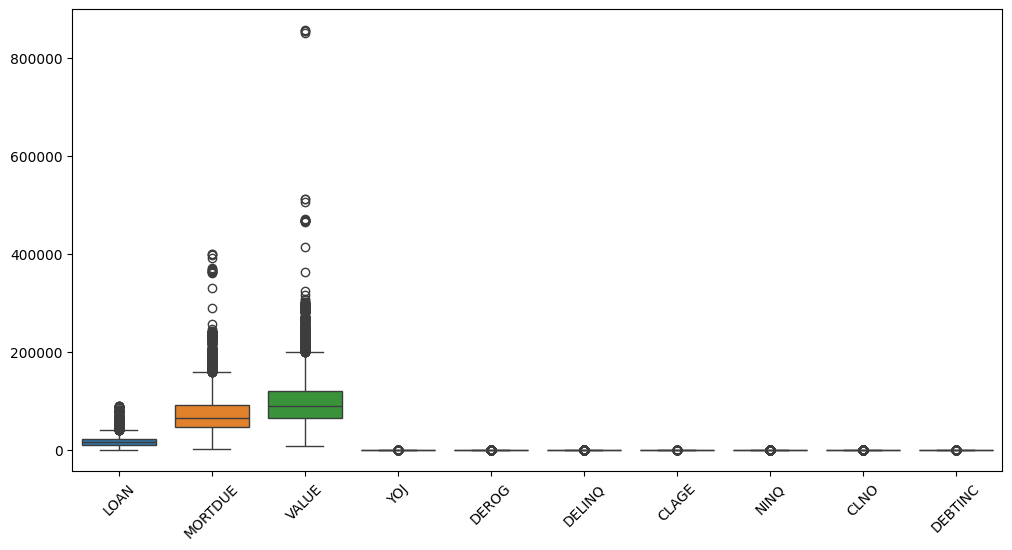

In [9]:
# Описательная статистика для числовых столбцов
data.describe()

# Визуализация выбросов с помощью boxplot
plt.figure(figsize=(12, 6))
sns.boxplot(data=data.drop(columns=['BAD']))
plt.xticks(rotation=45)
plt.show()

In [10]:
# Выбор числовых столбцов
numerical_columns = data.select_dtypes(include=['number']).columns

# Заполнение пропущенных значений медианой
data[numerical_columns] = data[numerical_columns].fillna(data[numerical_columns].median())

In [11]:
data.head()

,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
0,1,1100,25860.0,39025.0,HomeImp,Other,10.5,0.0,0.0,94.366667,1.0,9.0,34.818262
1,1,1300,70053.0,68400.0,HomeImp,Other,7.0,0.0,2.0,121.833333,0.0,14.0,34.818262
2,1,1500,13500.0,16700.0,HomeImp,Other,4.0,0.0,0.0,149.466667,1.0,10.0,34.818262
3,1,1500,65019.0,89235.5,NaN,NaN,7.0,0.0,0.0,173.466667,1.0,20.0,34.818262
4,0,1700,97800.0,112000.0,HomeImp,Office,3.0,0.0,0.0,93.333333,0.0,14.0,34.818262


In [12]:
# Проверка на пропущенные значения
data.isnull().sum()

,0
BAD,0
LOAN,0
MORTDUE,0
VALUE,0
REASON,252
JOB,279
YOJ,0
DEROG,0
DELINQ,0
CLAGE,0


In [13]:
# Выбор категориальных столбцов
categorical_columns = data.select_dtypes(include=['object']).columns

# Заполнение пропущенных значений модой
data[categorical_columns] = data[categorical_columns].fillna(data[categorical_columns].mode().iloc[0])

In [14]:
# Проверка на пропущенные значения
data.isnull().sum()

,0
BAD,0
LOAN,0
MORTDUE,0
VALUE,0
REASON,0
JOB,0
YOJ,0
DEROG,0
DELINQ,0
CLAGE,0


In [ ]:
# Расчет квартилей и IQR
Q1 = data[numerical_columns].quantile(0.25)
Q3 = data[numerical_columns].quantile(0.75)
IQR = Q3 - Q1

# Удаление выбросов
condition = ~((data[numerical_columns] < (Q1 - 1.5 * IQR)) | (data[numerical_columns] > (Q3 + 1.5 * IQR))).any(axis=1)
data = data[condition]

In [ ]:
# Количество строк до и после удаления выбросов
print(f"Количество строк до удаления выбросов: {len(data)}")
data = data[condition]
print(f"Количество строк после удаления выбросов: {len(data)}")

Количество строк до удаления выбросов: 2999
Количество строк после удаления выбросов: 2999


<ipython-input-16-5d2e4a14d108>:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  data = data[condition]


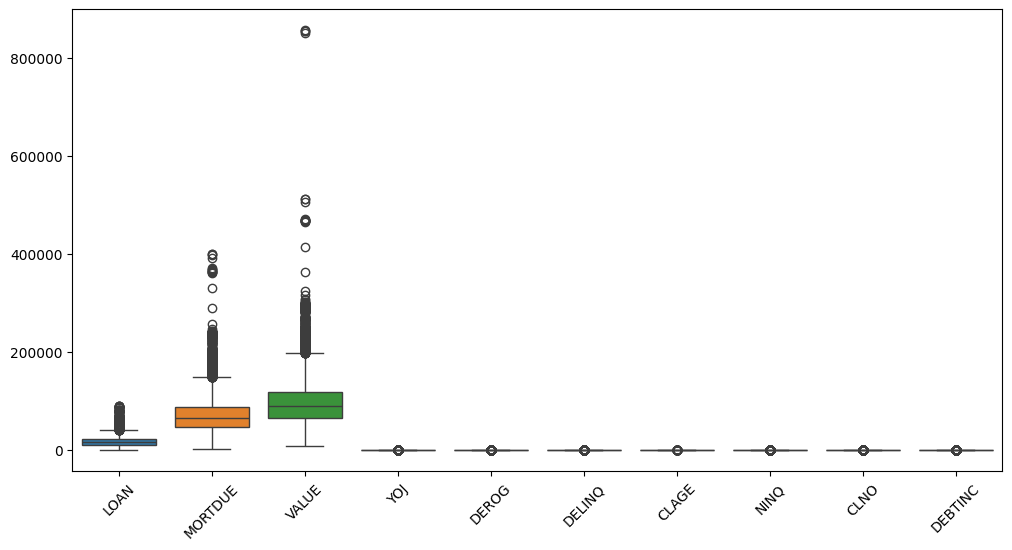

In [ ]:
# Визуализация выбросов с помощью boxplot
plt.figure(figsize=(12, 6))
sns.boxplot(data=data.drop(columns=['BAD']))
plt.xticks(rotation=45)
plt.show()

In [ ]:
# Расчет границ
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Вывод границ для каждого столбца
for col in numerical_columns:
    print(f"Столбец {col}:")
    print(f"Нижняя граница: {lower_bound[col]}, Верхняя граница: {upper_bound[col]}")
    print(f"Минимум: {data[col].min()}, Максимум: {data[col].max()}")
    print()

Столбец BAD:
Нижняя граница: 0.0, Верхняя граница: 0.0
Минимум: 0, Максимум: 0

Столбец LOAN:
Нижняя граница: -7200.0, Верхняя граница: 41600.0
Минимум: 1700, Максимум: 41100

Столбец MORTDUE:
Нижняя граница: -11952.875, Верхняя граница: 148292.125
Минимум: 2619.0, Максимум: 147696.0

Столбец VALUE:
Нижняя граница: -12283.375, Верхняя граница: 197777.625
Минимум: 8000.0, Максимум: 197722.0

Столбец YOJ:
Нижняя граница: -10.5, Верхняя граница: 25.5
Минимум: 0.0, Максимум: 25.0

Столбец DEROG:
Нижняя граница: 0.0, Верхняя граница: 0.0
Минимум: 0.0, Максимум: 0.0

Столбец DELINQ:
Нижняя граница: 0.0, Верхняя граница: 0.0
Минимум: 0.0, Максимум: 0.0

Столбец CLAGE:
Нижняя граница: -47.28601216625, Верхняя граница: 391.80050032375
Минимум: 20.759215295, Максимум: 380.27804051

Столбец NINQ:
Нижняя граница: -3.0, Верхняя граница: 5.0
Минимум: 0.0, Максимум: 5.0

Столбец CLNO:
Нижняя граница: -1.5, Верхняя граница: 42.5
Минимум: 0.0, Максимум: 42.0

Столбец DEBTINC:
Нижняя граница: 19.9830604

In [15]:
# Кодирование категориальных переменных с помощью LabelEncoder
label_encoder = LabelEncoder()
categorical_columns = ['REASON', 'JOB']  # Замените на реальные категориальные столбцы
for col in categorical_columns:
    data[col] = label_encoder.fit_transform(data[col])

# Просмотр измененных данных
data.head()

,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
0,1,1100,25860.0,39025.0,1,2,10.5,0.0,0.0,94.366667,1.0,9.0,34.818262
1,1,1300,70053.0,68400.0,1,2,7.0,0.0,2.0,121.833333,0.0,14.0,34.818262
2,1,1500,13500.0,16700.0,1,2,4.0,0.0,0.0,149.466667,1.0,10.0,34.818262
3,1,1500,65019.0,89235.5,0,2,7.0,0.0,0.0,173.466667,1.0,20.0,34.818262
4,0,1700,97800.0,112000.0,1,1,3.0,0.0,0.0,93.333333,0.0,14.0,34.818262


In [16]:
# Проверка типов данных
print(data.dtypes)

BAD          int64
LOAN         int64
MORTDUE    float64
VALUE      float64
REASON       int64
JOB          int64
YOJ        float64
DEROG      float64
DELINQ     float64
CLAGE      float64
NINQ       float64
CLNO       float64
DEBTINC    float64
dtype: object


In [19]:
X = data.drop(columns=['BAD'])
y = data['BAD']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Обучающая выборка: {X_train.shape}, {y_train.shape}")
print(f"Тестовая выборка: {X_test.shape}, {y_test.shape}")

Обучающая выборка: (4768, 12), (4768,)
Тестовая выборка: (1192, 12), (1192,)


In [20]:
# Масштабирование данных
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Подготовка метрик
Напишите функцию, которая выводит
метрики модели и рисует матрицу ошибок. Используйте метрики Accuracy,Precision, Recall и обязательно  Каппу Коэна -  
sklearn.metrics.accuracy_score

sklearn.metrics.

precision_recall_fscore_support

sklearn.metricscohen_kappa_score
Матрицу ошибок отрисовывайте с помощью
sklearn.metrics.ConfusionMatrixDisplay().plot

In [21]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, cohen_kappa_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

def evaluate_model(y_true, y_pred, model_name="Model"):
    # Вычисление метрик
    accuracy = accuracy_score(y_true, y_pred)
    precision, recall, f1_score, _ = precision_recall_fscore_support(y_true, y_pred, average='binary')
    kappa = cohen_kappa_score(y_true, y_pred)

    # Вывод метрик
    print(f"Метрики для модели '{model_name}':")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1_score:.4f}")
    print(f"Cohen's Kappa: {kappa:.4f}")
    print()

    # Визуализация матрицы ошибок
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, cmap='Blues', display_labels=['Good (0)', 'Bad (1)'])
    plt.title(f"Матрица ошибок для модели '{model_name}'")
    plt.show()

# Обучение
Постройте модели классификации с использованием
всех инструментов, которые мы применяли для
регрессии, включая варианты нейронных сетей с
подборкой параметров. Вместо линейной регрессии используйте
логистическую регрессию
sklearn.linear_model import
LogisticRegression

Вместо других регрессоров используйте
соответствующие классификаторы, например,
вместо DecisionTreeRegressor –
DecisionTreeClassifier

In [22]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, cohen_kappa_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd

In [24]:
print("Распределение классов в y:")
print(y.value_counts())

Распределение классов в y:
BAD
0    4771
1    1189
Name: count, dtype: int64


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Метрики для модели 'Logistic Regression':
Accuracy: 0.7081
Precision: 0.4014
Recall: 0.6377
F1-Score: 0.4927
Cohen's Kappa: 0.3023



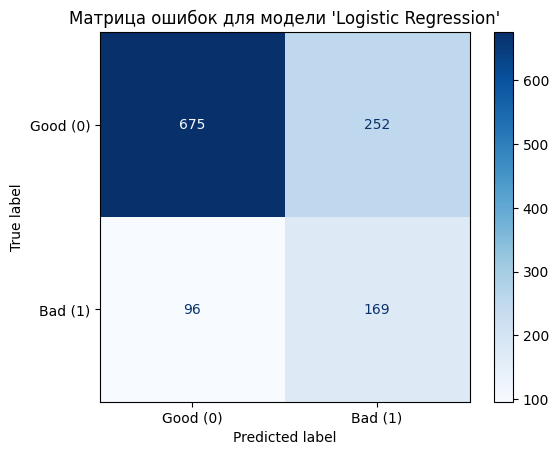

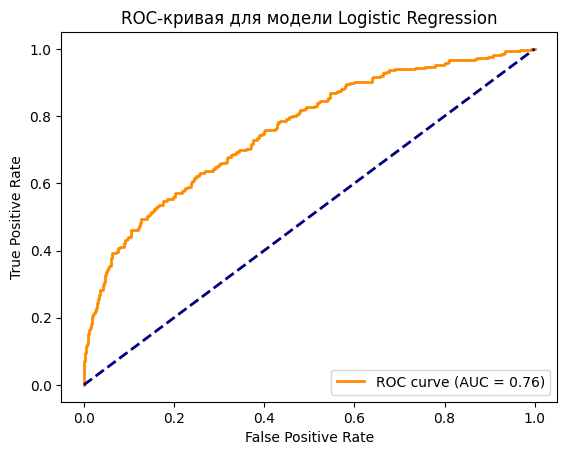

Метрики для модели 'Ridge Classifier':
Accuracy: 0.7433
Precision: 0.4432
Recall: 0.6038
F1-Score: 0.5112
Cohen's Kappa: 0.3426



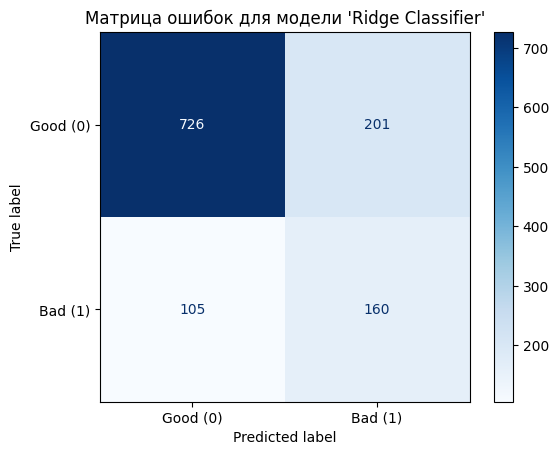

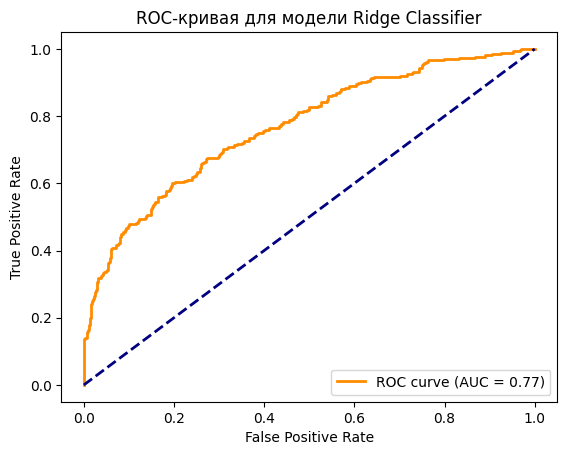

Метрики для модели 'Lasso Logistic Regression':
Accuracy: 0.7324
Precision: 0.4297
Recall: 0.6226
F1-Score: 0.5085
Cohen's Kappa: 0.3330



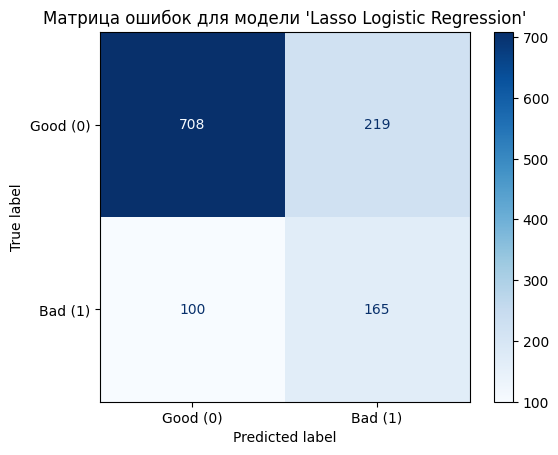

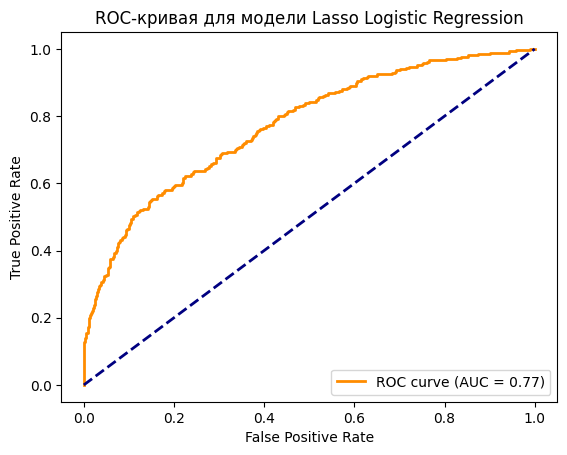

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Метрики для модели 'Elastic-Net Logistic Regression':
Accuracy: 0.6862
Precision: 0.2599
Recall: 0.2226
F1-Score: 0.2398
Cohen's Kappa: 0.0436



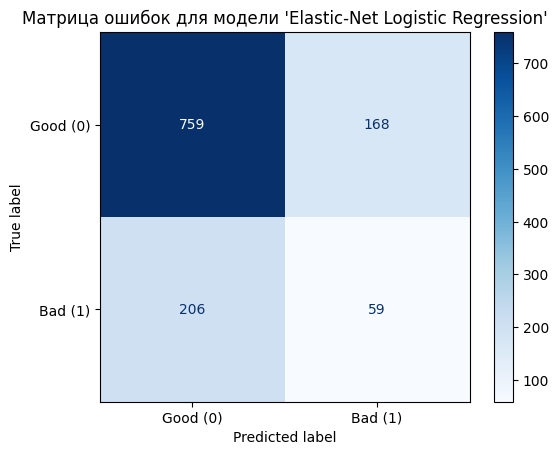

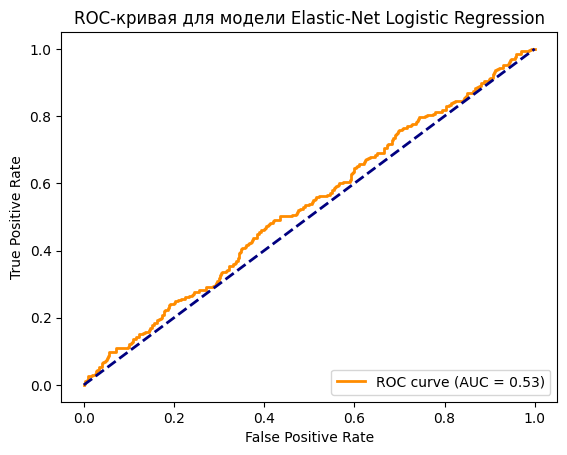

Метрики для модели 'Decision Tree':
Accuracy: 0.8523
Precision: 0.6878
Recall: 0.6151
F1-Score: 0.6494
Cohen's Kappa: 0.5563



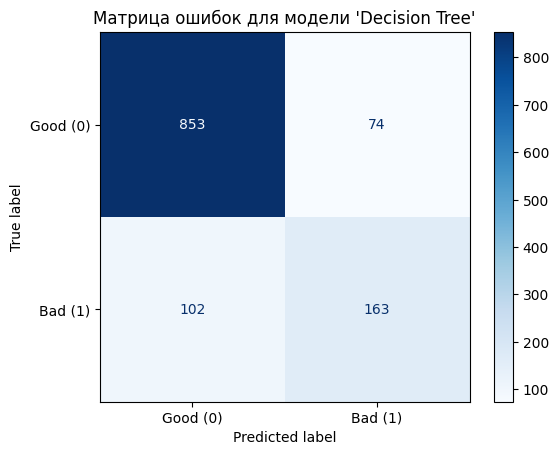

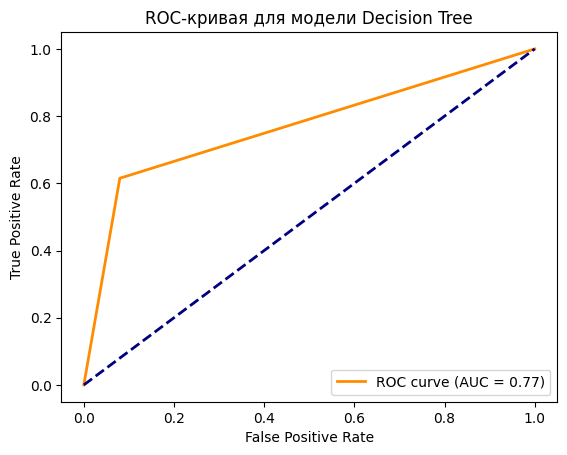

Метрики для модели 'Decision Tree (Max Depth=5)':
Accuracy: 0.8557
Precision: 0.6356
Recall: 0.8226
F1-Score: 0.7171
Cohen's Kappa: 0.6224



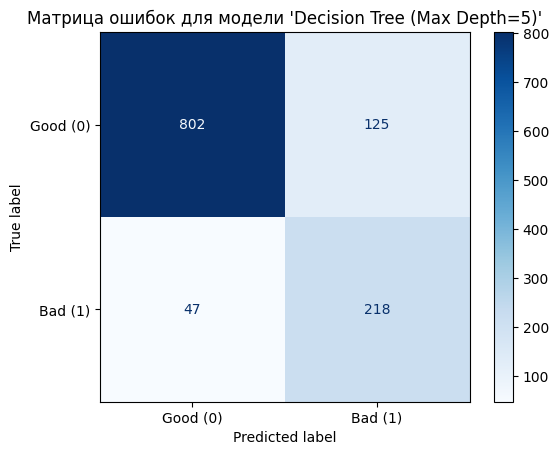

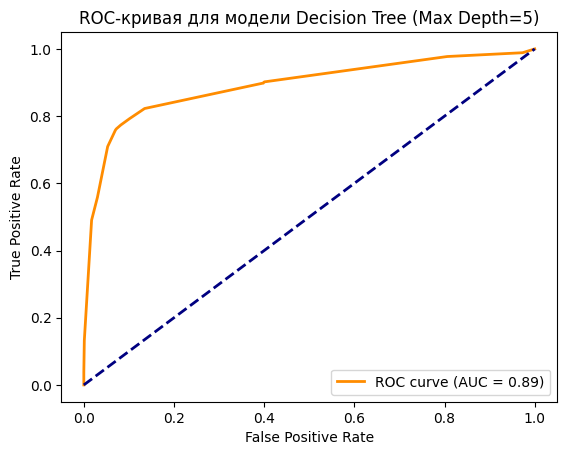

Метрики для модели 'Decision Tree (Min Samples Split=10)':
Accuracy: 0.8523
Precision: 0.6508
Recall: 0.7245
F1-Score: 0.6857
Cohen's Kappa: 0.5896



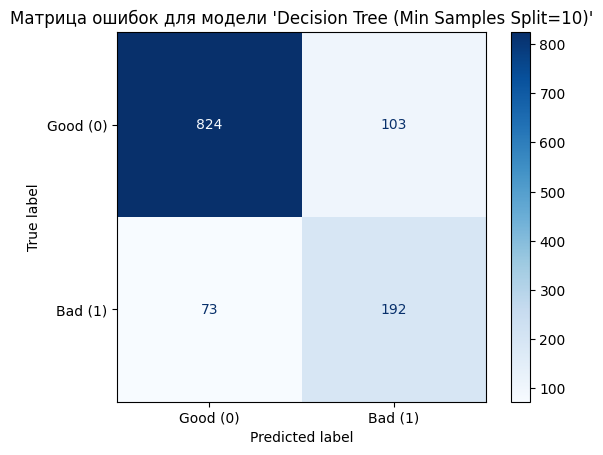

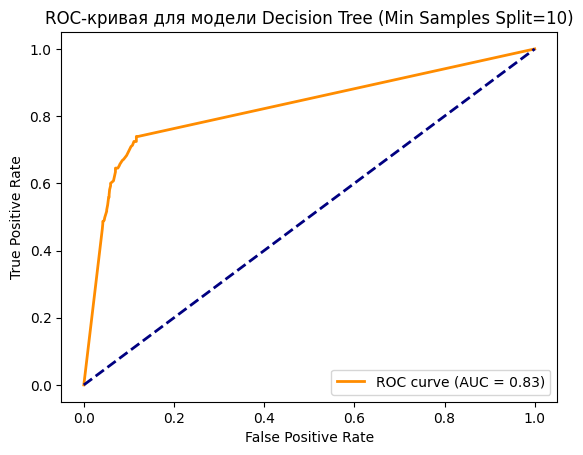

Метрики для модели 'Decision Tree (Pruning)':
Accuracy: 0.8649
Precision: 0.6722
Recall: 0.7660
F1-Score: 0.7160
Cohen's Kappa: 0.6279



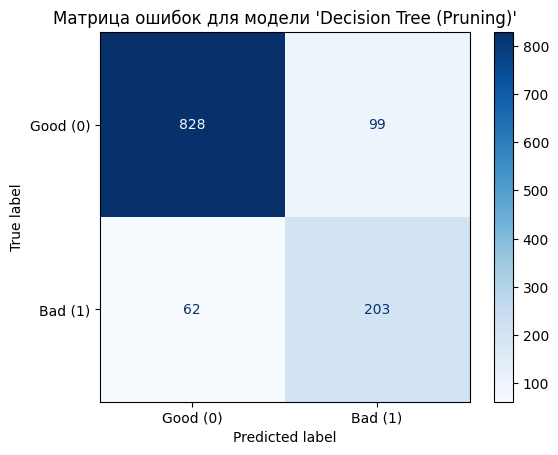

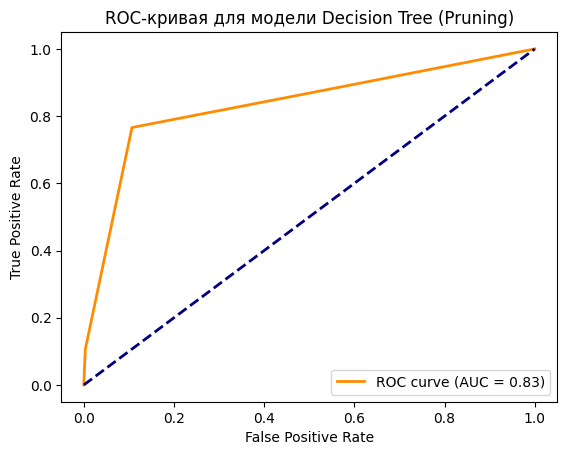

Метрики для модели 'Bagging Classifier':
Accuracy: 0.8800
Precision: 0.8177
Recall: 0.5925
F1-Score: 0.6871
Cohen's Kappa: 0.6152



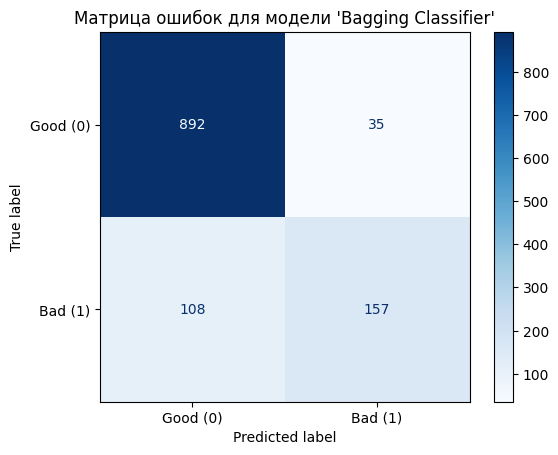

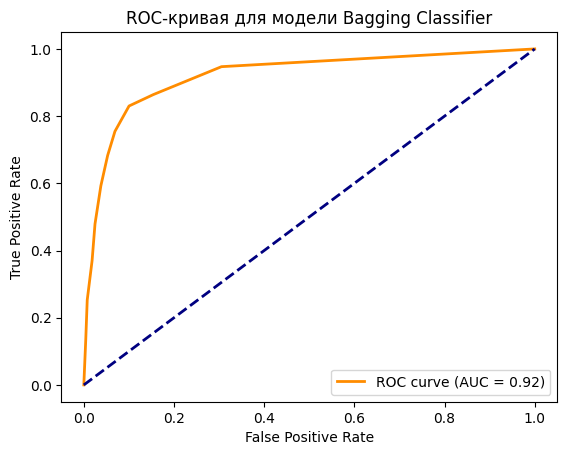

Метрики для модели 'Gradient Boosting':
Accuracy: 0.8951
Precision: 0.8535
Recall: 0.6377
F1-Score: 0.7300
Cohen's Kappa: 0.6666



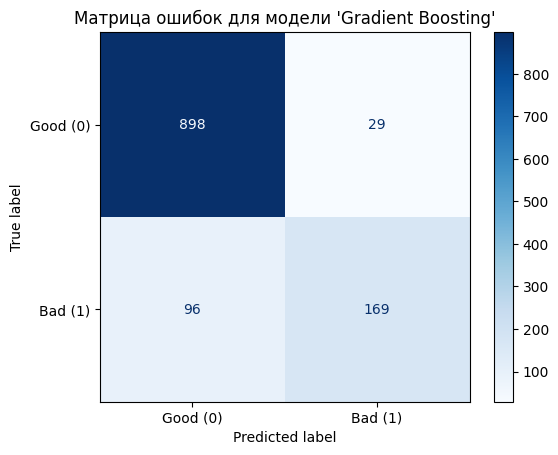

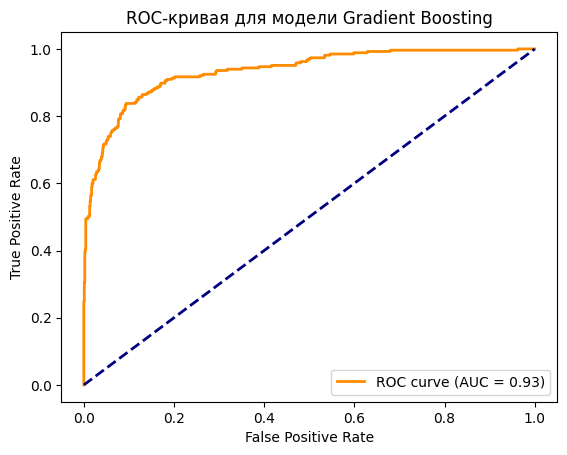

Метрики для модели 'Random Forest':
Accuracy: 0.9044
Precision: 0.8912
Recall: 0.6491
F1-Score: 0.7511
Cohen's Kappa: 0.6937



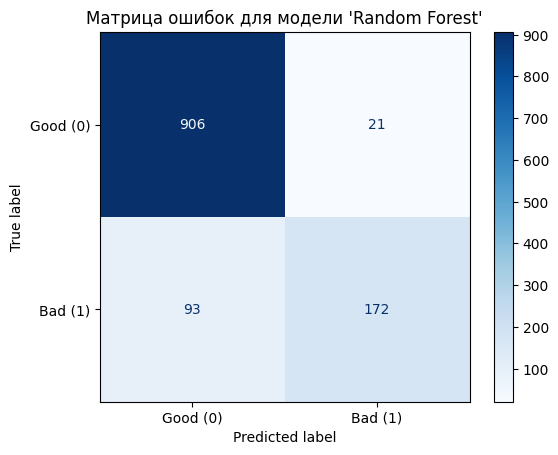

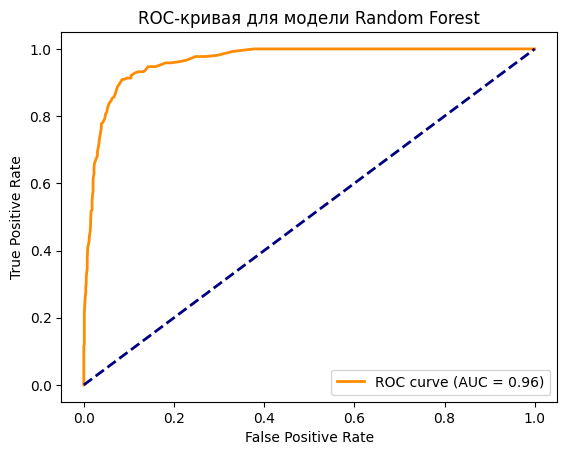

Метрики для модели 'SVM':
Accuracy: 0.6317
Precision: 0.2746
Recall: 0.4000
F1-Score: 0.3257
Cohen's Kappa: 0.0842



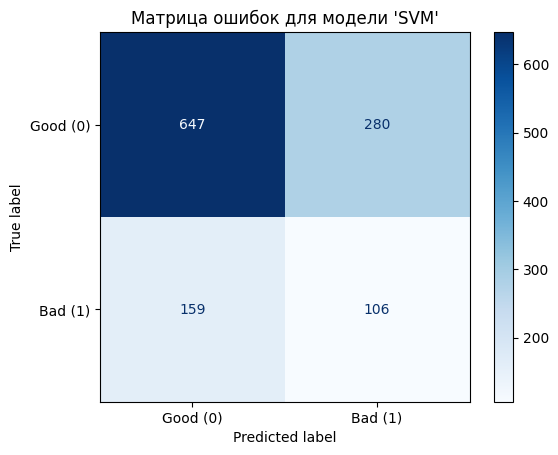

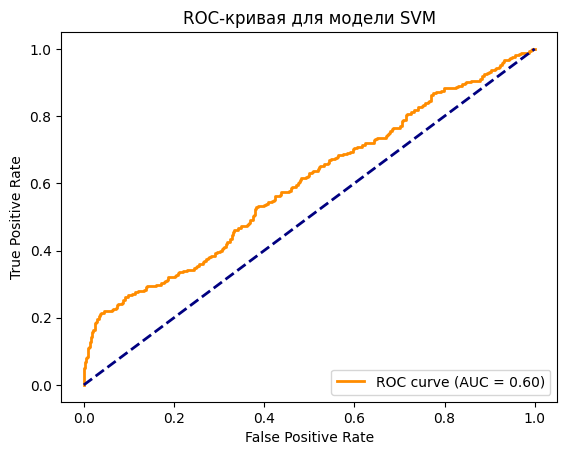

Метрики для модели 'KNN':
Accuracy: 0.8087
Precision: 0.6504
Recall: 0.3019
F1-Score: 0.4124
Cohen's Kappa: 0.3160



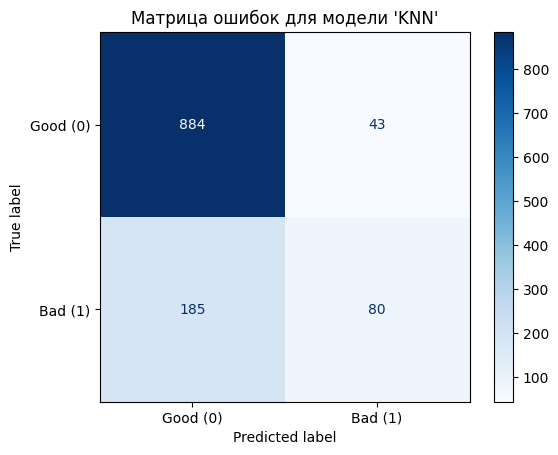

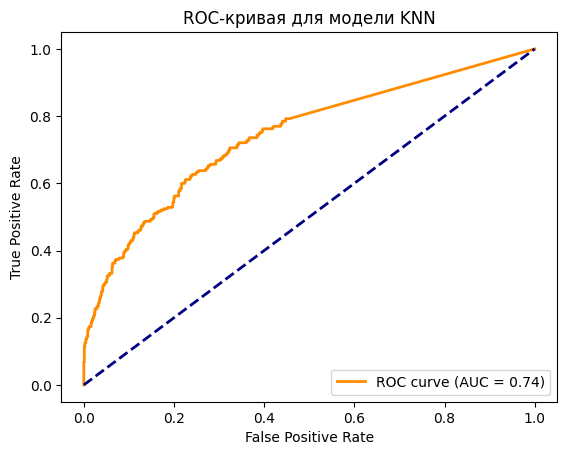

Метрики для модели 'Neural Network (MLP)':
Accuracy: 0.7802
Precision: 0.8000
Recall: 0.0151
F1-Score: 0.0296
Cohen's Kappa: 0.0216



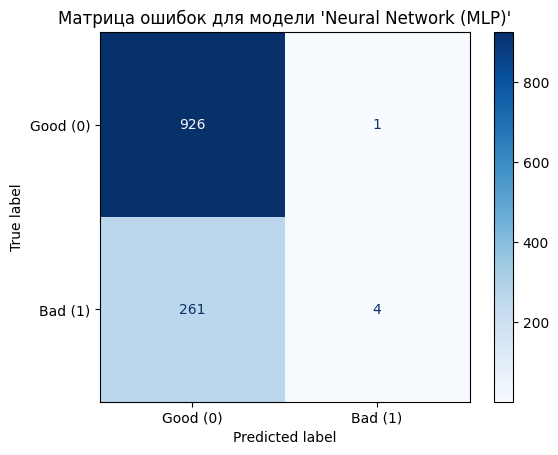

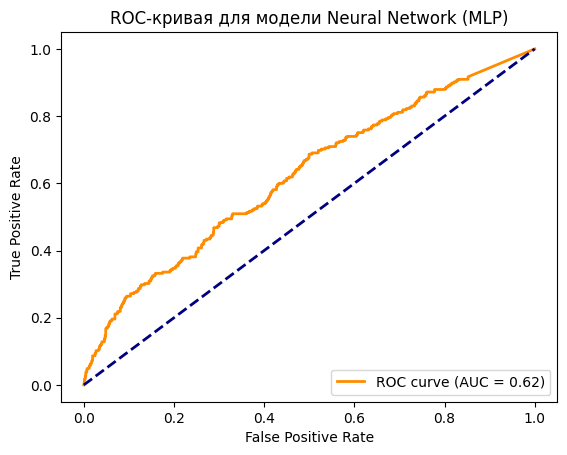

In [26]:
from sklearn.metrics import roc_curve, roc_auc_score, auc
import matplotlib.pyplot as plt

# Функция для построения ROC-кривой
def plot_roc_curve(y_true, y_pred_proba, model_name="Model"):
    # Вычисляем FPR, TPR и пороги
    fpr, tpr, thresholds = roc_curve(y_true, y_pred_proba)

    # Вычисляем AUC-ROC
    roc_auc = roc_auc_score(y_true, y_pred_proba)

    # Строим ROC-кривую
    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC-кривая для модели {model_name}')
    plt.legend(loc="lower right")
    plt.show()

# 1. Логистическая регрессия
log_reg = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
log_reg.fit(X_train, y_train)
y_pred_log_reg = log_reg.predict(X_test)
y_pred_log_reg_proba = log_reg.predict_proba(X_test)[:, 1]  # Вероятности для положительного класса
evaluate_model(y_test, y_pred_log_reg, model_name="Logistic Regression")
plot_roc_curve(y_test, y_pred_log_reg_proba, model_name="Logistic Regression")

# 2. Гребневая регрессия
ridge_clf = RidgeClassifier(random_state=42, class_weight='balanced')
ridge_clf.fit(X_train, y_train)
y_pred_ridge = ridge_clf.predict(X_test)
y_pred_ridge_proba = ridge_clf.decision_function(X_test)  # Функция принятия решений
evaluate_model(y_test, y_pred_ridge, model_name="Ridge Classifier")
plot_roc_curve(y_test, y_pred_ridge_proba, model_name="Ridge Classifier")

# 3. Лассо регрессия
lasso_clf = LogisticRegression(penalty='l1', solver='liblinear', random_state=42, class_weight='balanced')
lasso_clf.fit(X_train, y_train)
y_pred_lasso = lasso_clf.predict(X_test)
y_pred_lasso_proba = lasso_clf.predict_proba(X_test)[:, 1]  # Вероятности для положительного класса
evaluate_model(y_test, y_pred_lasso, model_name="Lasso Logistic Regression")
plot_roc_curve(y_test, y_pred_lasso_proba, model_name="Lasso Logistic Regression")

# 4. Эластичная сетевая регрессия
elastic_clf = LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=0.5, random_state=42, class_weight='balanced')
elastic_clf.fit(X_train, y_train)
y_pred_elastic = elastic_clf.predict(X_test)
y_pred_elastic_proba = elastic_clf.predict_proba(X_test)[:, 1]  # Вероятности для положительного класса
evaluate_model(y_test, y_pred_elastic, model_name="Elastic-Net Logistic Regression")
plot_roc_curve(y_test, y_pred_elastic_proba, model_name="Elastic-Net Logistic Regression")

# 5. Деревья решений
tree_clf = DecisionTreeClassifier(random_state=42, class_weight='balanced')
tree_clf.fit(X_train, y_train)
y_pred_tree = tree_clf.predict(X_test)
y_pred_tree_proba = tree_clf.predict_proba(X_test)[:, 1]  # Вероятности для положительного класса
evaluate_model(y_test, y_pred_tree, model_name="Decision Tree")
plot_roc_curve(y_test, y_pred_tree_proba, model_name="Decision Tree")

# 6. Деревья решений с ограничением глубины
tree_depth_clf = DecisionTreeClassifier(max_depth=5, random_state=42, class_weight='balanced')
tree_depth_clf.fit(X_train, y_train)
y_pred_tree_depth = tree_depth_clf.predict(X_test)
y_pred_tree_depth_proba = tree_depth_clf.predict_proba(X_test)[:, 1]  # Вероятности для положительного класса
evaluate_model(y_test, y_pred_tree_depth, model_name="Decision Tree (Max Depth=5)")
plot_roc_curve(y_test, y_pred_tree_depth_proba, model_name="Decision Tree (Max Depth=5)")

# 7. Деревья решений с ограничением числа элементов на листе
tree_leaf_clf = DecisionTreeClassifier(min_samples_split=10, random_state=42, class_weight='balanced')
tree_leaf_clf.fit(X_train, y_train)
y_pred_tree_leaf = tree_leaf_clf.predict(X_test)
y_pred_tree_leaf_proba = tree_leaf_clf.predict_proba(X_test)[:, 1]  # Вероятности для положительного класса
evaluate_model(y_test, y_pred_tree_leaf, model_name="Decision Tree (Min Samples Split=10)")
plot_roc_curve(y_test, y_pred_tree_leaf_proba, model_name="Decision Tree (Min Samples Split=10)")

# 8. Деревья решений с обрезкой ветвей
tree_pruning_clf = DecisionTreeClassifier(ccp_alpha=0.01, random_state=42, class_weight='balanced')
tree_pruning_clf.fit(X_train, y_train)
y_pred_tree_pruning = tree_pruning_clf.predict(X_test)
y_pred_tree_pruning_proba = tree_pruning_clf.predict_proba(X_test)[:, 1]  # Вероятности для положительного класса
evaluate_model(y_test, y_pred_tree_pruning, model_name="Decision Tree (Pruning)")
plot_roc_curve(y_test, y_pred_tree_pruning_proba, model_name="Decision Tree (Pruning)")

# 9. Бэггинг
base_estimator = DecisionTreeClassifier(class_weight='balanced', random_state=42)
bagging_clf = BaggingClassifier(estimator=base_estimator, random_state=42)
bagging_clf.fit(X_train, y_train)
y_pred_bagging = bagging_clf.predict(X_test)
y_pred_bagging_proba = bagging_clf.predict_proba(X_test)[:, 1]  # Вероятности для положительного класса
evaluate_model(y_test, y_pred_bagging, model_name="Bagging Classifier")
plot_roc_curve(y_test, y_pred_bagging_proba, model_name="Bagging Classifier")

# 10. Градиентный бустинг
gb_clf = GradientBoostingClassifier(random_state=42)
gb_clf.fit(X_train, y_train)
y_pred_gb = gb_clf.predict(X_test)
y_pred_gb_proba = gb_clf.predict_proba(X_test)[:, 1]  # Вероятности для положительного класса
evaluate_model(y_test, y_pred_gb, model_name="Gradient Boosting")
plot_roc_curve(y_test, y_pred_gb_proba, model_name="Gradient Boosting")

# 11. Случайные леса
rf_clf = RandomForestClassifier(random_state=42, class_weight='balanced')
rf_clf.fit(X_train, y_train)
y_pred_rf = rf_clf.predict(X_test)
y_pred_rf_proba = rf_clf.predict_proba(X_test)[:, 1]  # Вероятности для положительного класса
evaluate_model(y_test, y_pred_rf, model_name="Random Forest")
plot_roc_curve(y_test, y_pred_rf_proba, model_name="Random Forest")

# 12. Метод опорных векторов (SVM)
svm_clf = SVC(random_state=42, class_weight='balanced', probability=True)  # Добавим probability=True для predict_proba
svm_clf.fit(X_train, y_train)
y_pred_svm = svm_clf.predict(X_test)
y_pred_svm_proba = svm_clf.predict_proba(X_test)[:, 1]  # Вероятности для положительного класса
evaluate_model(y_test, y_pred_svm, model_name="SVM")
plot_roc_curve(y_test, y_pred_svm_proba, model_name="SVM")

# 13. K-ближайших соседей (KNN)
knn_clf = KNeighborsClassifier(weights='distance')
knn_clf.fit(X_train, y_train)
y_pred_knn = knn_clf.predict(X_test)
y_pred_knn_proba = knn_clf.predict_proba(X_test)[:, 1]  # Вероятности для положительного класса
evaluate_model(y_test, y_pred_knn, model_name="KNN")
plot_roc_curve(y_test, y_pred_knn_proba, model_name="KNN")

# 14. Нейронная сеть (MLP)
mlp_clf = MLPClassifier(random_state=42, max_iter=1000)  # Убрали class_weight
mlp_clf.fit(X_train, y_train)
y_pred_mlp = mlp_clf.predict(X_test)
y_pred_mlp_proba = mlp_clf.predict_proba(X_test)[:, 1]  # Вероятности для положительного класса
evaluate_model(y_test, y_pred_mlp, model_name="Neural Network (MLP)")
plot_roc_curve(y_test, y_pred_mlp_proba, model_name="Neural Network (MLP)")

# Ансамблевые модели
**Постройте также ансамблевые модели (не леса
деревьев решений) с помощью инcтрументов
вотинга и стекинга. sklearn.ensemble.VotingClassifier
sklearn.ensemble.StackingClassifier**

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Метрики для модели 'Voting Classifier (Hard Voting)':
Accuracy: 0.8062
Precision: 0.5607
Recall: 0.5925
F1-Score: 0.5761
Cohen's Kappa: 0.4507



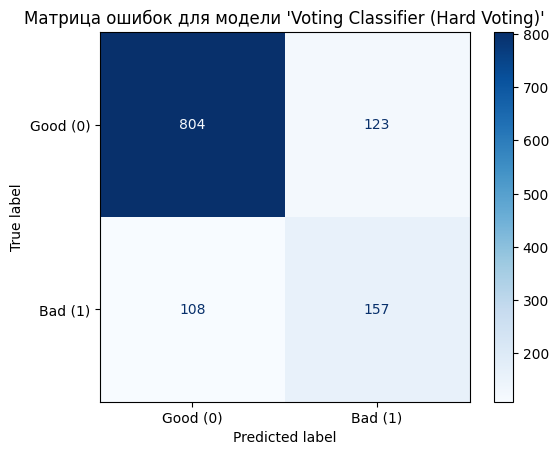

Voting Classifier (Hard Voting) не поддерживает predict_proba для ROC-кривой.


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Метрики для модели 'Voting Classifier (Soft Voting)':
Accuracy: 0.8574
Precision: 0.7273
Recall: 0.5736
F1-Score: 0.6414
Cohen's Kappa: 0.5539



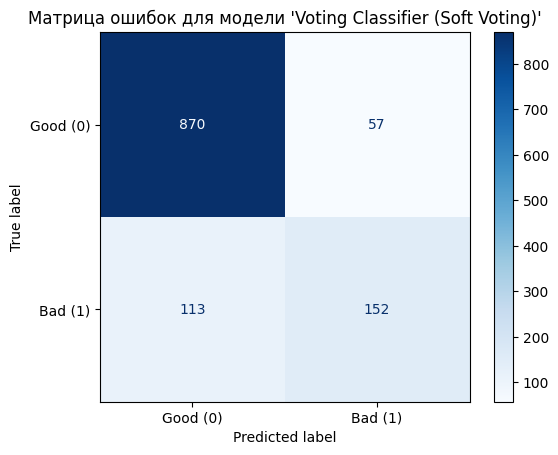

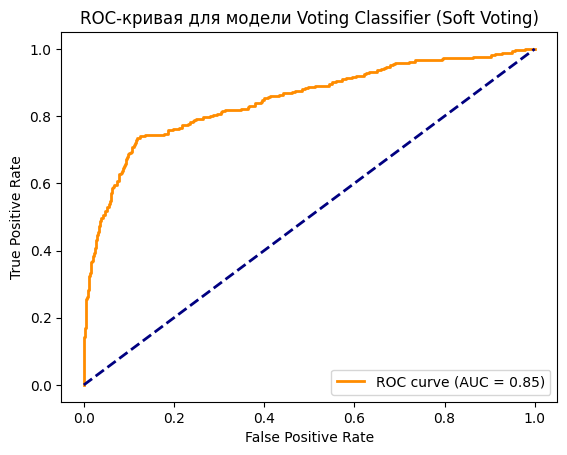

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

Метрики для модели 'Stacking Classifier':
Accuracy: 0.8121
Precision: 0.5577
Recall: 0.7472
F1-Score: 0.6387
Cohen's Kappa: 0.5153



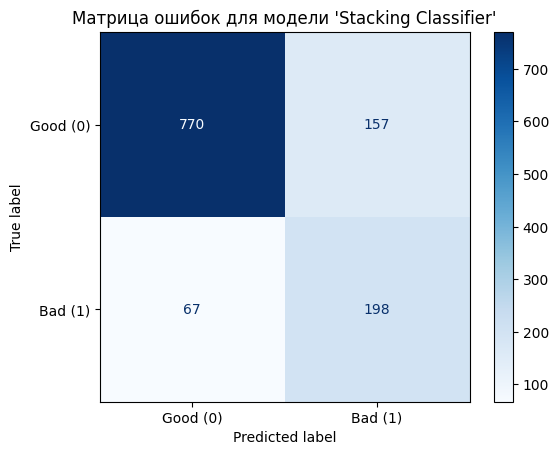

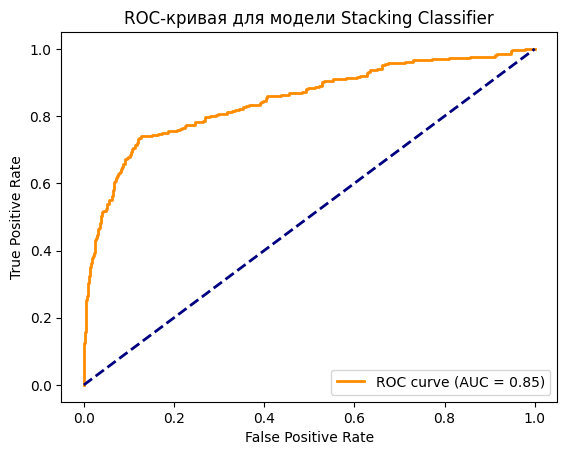

In [28]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Функция для построения ROC-кривой
def plot_roc_curve(y_true, y_pred_proba, model_name="Model"):
    # Вычисляем FPR, TPR и пороги
    fpr, tpr, thresholds = roc_curve(y_true, y_pred_proba)

    # Вычисляем AUC-ROC
    roc_auc = roc_auc_score(y_true, y_pred_proba)

    # Строим ROC-кривую
    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC-кривая для модели {model_name}')
    plt.legend(loc="lower right")
    plt.show()

# 1. VotingClassifier (Hard Voting)
voting_clf = VotingClassifier(estimators=estimators, voting='hard')
voting_clf.fit(X_train, y_train)
y_pred_voting = voting_clf.predict(X_test)

# Оценка модели
evaluate_model(y_test, y_pred_voting, model_name="Voting Classifier (Hard Voting)")

# Для ROC-кривой используем вероятности (если доступно)
if hasattr(voting_clf, "predict_proba"):
    y_pred_voting_proba = voting_clf.predict_proba(X_test)[:, 1]
    plot_roc_curve(y_test, y_pred_voting_proba, model_name="Voting Classifier (Hard Voting)")
else:
    print("Voting Classifier (Hard Voting) не поддерживает predict_proba для ROC-кривой.")

# 2. VotingClassifier (Soft Voting)
voting_clf_soft = VotingClassifier(estimators=estimators, voting='soft')
voting_clf_soft.fit(X_train, y_train)
y_pred_voting_soft = voting_clf_soft.predict(X_test)

# Оценка модели
evaluate_model(y_test, y_pred_voting_soft, model_name="Voting Classifier (Soft Voting)")

# Для ROC-кривой используем вероятности
y_pred_voting_soft_proba = voting_clf_soft.predict_proba(X_test)[:, 1]
plot_roc_curve(y_test, y_pred_voting_soft_proba, model_name="Voting Classifier (Soft Voting)")

# 3. StackingClassifier
stacking_clf = StackingClassifier(estimators=base_models, final_estimator=meta_model)
stacking_clf.fit(X_train, y_train)
y_pred_stacking = stacking_clf.predict(X_test)

# Оценка модели
evaluate_model(y_test, y_pred_stacking, model_name="Stacking Classifier")

# Для ROC-кривой используем вероятности
y_pred_stacking_proba = stacking_clf.predict_proba(X_test)[:, 1]
plot_roc_curve(y_test, y_pred_stacking_proba, model_name="Stacking Classifier")

# Нейронные сети в Keras
**Постройте нейронную сеть в Keras. В выходном слое используйте активационную
функцию sigmoid, в скрытых – любые.**

Epoch 1/50


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


120/120 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6817 - loss: 6350.0298 - val_accuracy: 0.8239 - val_loss: 184.1029
Epoch 2/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6769 - loss: 1737.7078 - val_accuracy: 0.8239 - val_loss: 21.1713
Epoch 3/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6806 - loss: 652.9052 - val_accuracy: 0.8155 - val_loss: 0.9201
Epoch 4/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6869 - loss: 228.0925 - val_accuracy: 0.8239 - val_loss: 1.3147
Epoch 5/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7054 - loss: 94.2138 - val_accuracy: 0.2002 - val_loss: 0.8099
Epoch 6/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7042 - loss: 72.3702 - val_accuracy: 0.8239 - val_loss: 0.4851
Epoch 7/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7080 - loss: 46.4081 - val_accuracy: 0.8239 - val_loss: 1.7394
Epoch 8/50
120/120 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7204 - loss: 29.4835 - val_accura

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


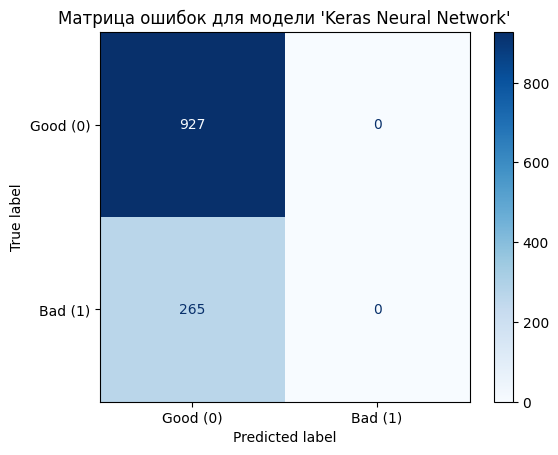

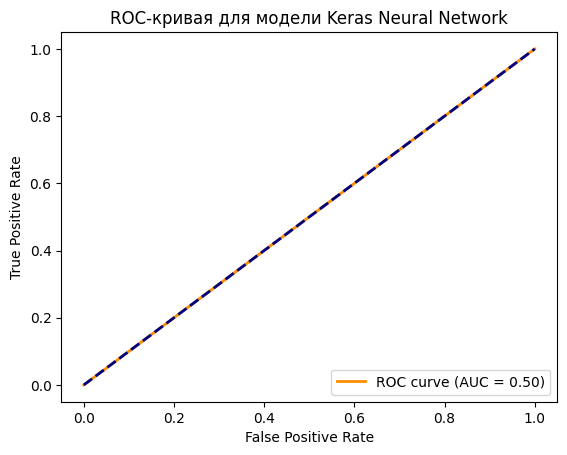

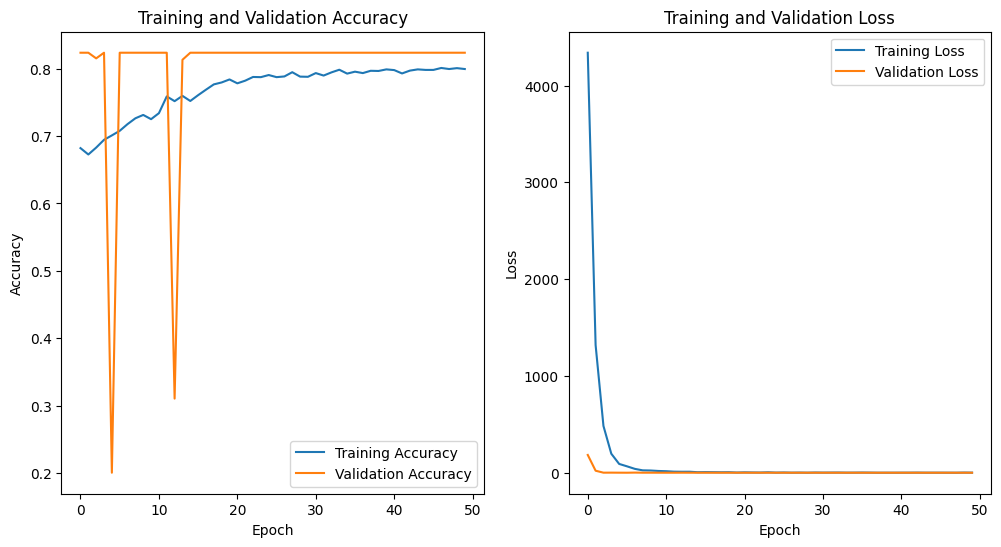

In [29]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, cohen_kappa_score, roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# 1. Создание модели
model = Sequential()

# Входной слой и первый скрытый слой
model.add(Dense(64, input_dim=X_train.shape[1], activation='relu'))  # ReLU активация
model.add(Dropout(0.5))  # Добавляем Dropout для предотвращения переобучения

# Второй скрытый слой
model.add(Dense(32, activation='relu'))  # ReLU активация
model.add(Dropout(0.5))  # Добавляем Dropout

# Выходной слой
model.add(Dense(1, activation='sigmoid'))  # Sigmoid активация для бинарной классификации

# Компиляция модели
model.compile(optimizer=Adam(learning_rate=0.001),  # Оптимизатор Adam
              loss='binary_crossentropy',  # Функция потерь для бинарной классификации
              metrics=['accuracy'])

# 2. Обучение модели
history = model.fit(X_train, y_train,
                    epochs=50,  # Количество эпох
                    batch_size=32,  # Размер батча
                    validation_split=0.2,  # Разделение на обучение и валидацию
                    verbose=1)  # Вывод процесса обучения

# 3. Оценка модели на тестовых данных
y_pred_keras = model.predict(X_test)
y_pred_keras_class = (y_pred_keras > 0.5).astype(int)  # Преобразуем вероятности в классы

# Вывод метрик
evaluate_model(y_test, y_pred_keras_class, model_name="Keras Neural Network")

# 4. Построение ROC-кривой
y_pred_keras_proba = y_pred_keras.flatten()  # Преобразуем в одномерный массив
plot_roc_curve(y_test, y_pred_keras_proba, model_name="Keras Neural Network")

# 5. Визуализация процесса обучения
plt.figure(figsize=(12, 6))

# График точности
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# График потерь
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

# Результаты Keras
**Обратите внимание, что в отличие от sklearn,
ваша сеть в Keras выдает не метки классов (0, 1) а
вероятности – непрерывное значение от 0 до 1.
Постройте ROC кривую и посчитайте AUC.
Посмотрите, как изменение порога отсечения влияет
на метрики.
Попробуйте использовать один из методов
нахождения оптимальной точки отсечения -
np.argmax(tpr - fpr)**

38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


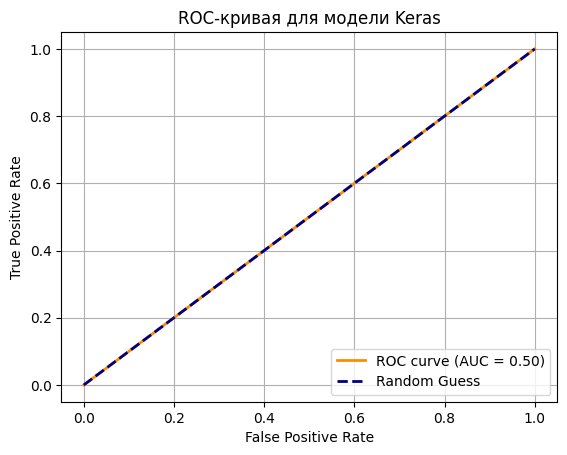

Оптимальный порог отсечения: inf
Метрики с оптимальным порогом отсечения (inf):
Accuracy: 0.7777
Precision: 0.0000
Recall: 0.0000
F1-Score: 0.0000

Влияние порога отсечения на метрики:
Порог | Accuracy | Precision | Recall | F1-Score
0.10  | 0.2223  | 0.2223  | 1.0000  | 0.3638
0.20  | 0.7777  | 0.0000  | 0.0000  | 0.0000
0.30  | 0.7777  | 0.0000  | 0.0000  | 0.0000
0.40  | 0.7777  | 0.0000  | 0.0000  | 0.0000
0.50  | 0.7777  | 0.0000  | 0.0000  | 0.0000
0.60  | 0.7777  | 0.0000  | 0.0000  | 0.0000
0.70  | 0.7777  | 0.0000  | 0.0000  | 0.0000
0.80  | 0.7777  | 0.0000  | 0.0000  | 0.0000
0.90  | 0.7777  | 0.0000  | 0.0000  | 0.0000


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [31]:
from sklearn.metrics import roc_curve, roc_auc_score, accuracy_score, precision_recall_fscore_support
import numpy as np
import matplotlib.pyplot as plt

# 1. Получение вероятностей от модели Keras
y_pred_keras_proba = model.predict(X_test).flatten()  # Вероятности принадлежности к классу 1

# 2. Построение ROC-кривой и вычисление AUC
fpr, tpr, thresholds = roc_curve(y_test, y_pred_keras_proba)
roc_auc = roc_auc_score(y_test, y_pred_keras_proba)

# Визуализация ROC-кривой
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривая для модели Keras')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# 3. Нахождение оптимального порога отсечения
# Используем индекс, максимизирующий разницу между TPR и FPR (Youden's J statistic)
optimal_idx = np.argmax(tpr - fpr)  # Индекс оптимального порога
optimal_threshold = thresholds[optimal_idx]  # Оптимальный порог

print(f"Оптимальный порог отсечения: {optimal_threshold:.4f}")

# 4. Применение оптимального порога для получения меток классов
y_pred_keras_optimal = (y_pred_keras_proba >= optimal_threshold).astype(int)

# 5. Оценка метрик с оптимальным порогом
accuracy = accuracy_score(y_test, y_pred_keras_optimal)
precision, recall, f1_score, _ = precision_recall_fscore_support(y_test, y_pred_keras_optimal, average='binary')

print(f"Метрики с оптимальным порогом отсечения ({optimal_threshold:.4f}):")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1_score:.4f}")

# 6. Исследование влияния порога на метрики
thresholds_to_test = np.arange(0.1, 1.0, 0.1)  # Пороги от 0.1 до 0.9 с шагом 0.1
results = []

for threshold in thresholds_to_test:
    y_pred_threshold = (y_pred_keras_proba >= threshold).astype(int)
    accuracy = accuracy_score(y_test, y_pred_threshold)
    precision, recall, f1_score, _ = precision_recall_fscore_support(y_test, y_pred_threshold, average='binary', zero_division=0)  # Учитываем zero_division
    results.append((threshold, accuracy, precision, recall, f1_score))

# Вывод результатов
print("\nВлияние порога отсечения на метрики:")
print("Порог | Accuracy | Precision | Recall | F1-Score")
for result in results:
    print(f"{result[0]:.2f}  | {result[1]:.4f}  | {result[2]:.4f}  | {result[3]:.4f}  | {result[4]:.4f}")

# Дропаут
**Посмотрите, как величина дропаута влияет на
предотвращение переобучения в Keras**

Training model with dropout rate: 0.0
Training model with dropout rate: 0.2
Training model with dropout rate: 0.4
Training model with dropout rate: 0.6


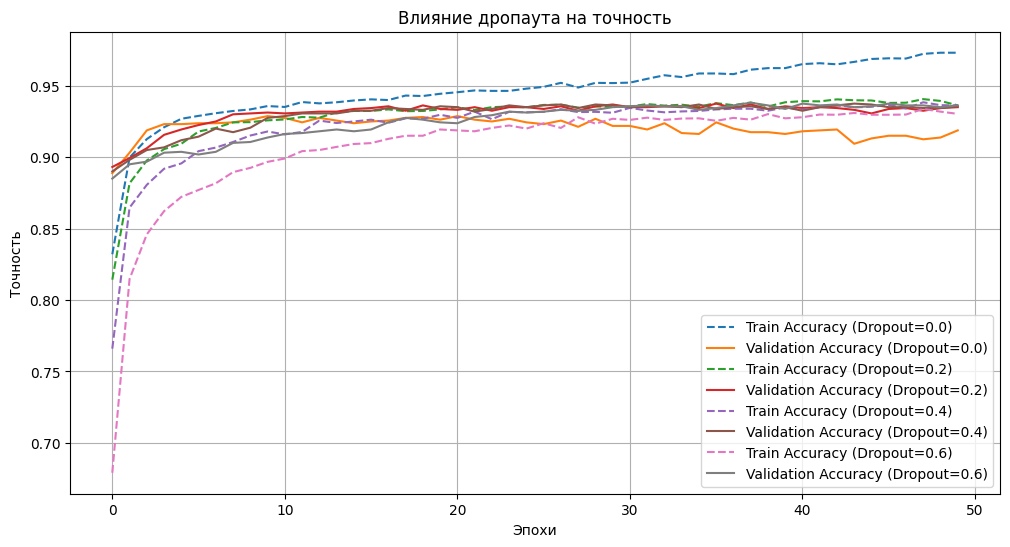

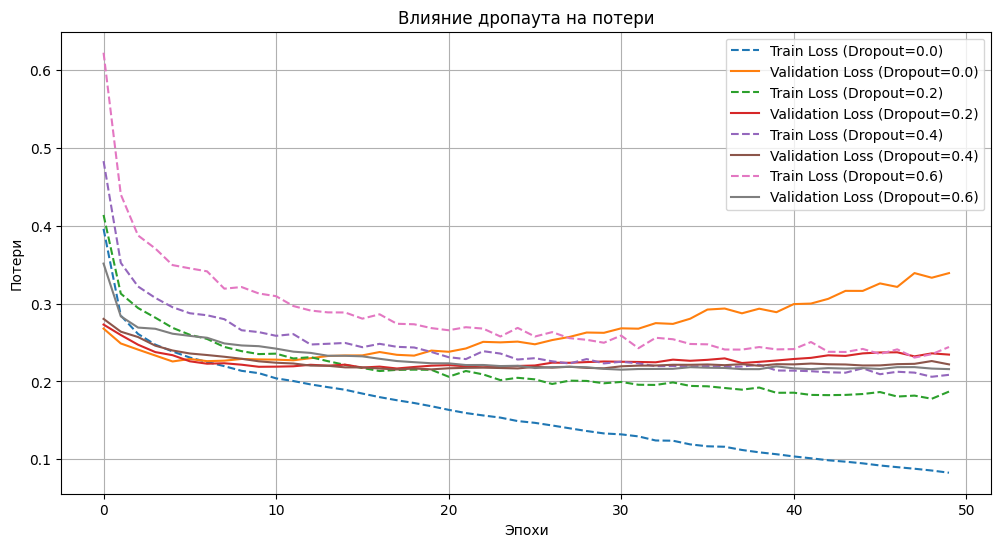

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification

# Генерация синтетических данных
X, y = make_classification(n_samples=10000, n_features=20, n_classes=2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Функция для создания модели с дропаутом
def create_model(dropout_rate):
    model = Sequential([
        Input(shape=(X_train.shape[1],)),  # Явное указание входного слоя
        Dense(64, activation='relu'),
        Dropout(dropout_rate),  # Добавляем дропаут
        Dense(32, activation='relu'),
        Dropout(dropout_rate),  # Добавляем дропаут
        Dense(1, activation='sigmoid')  # Выходной слой для бинарной классификации
    ])
    model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])
    return model

# Значения дропаута для исследования
dropout_rates = [0.0, 0.2, 0.4, 0.6]
histories = []

# Обучение моделей с разными значениями дропаута
for rate in dropout_rates:
    print(f"Training model with dropout rate: {rate}")
    model = create_model(rate)
    history = model.fit(X_train, y_train, epochs=50, batch_size=32, validation_split=0.2, verbose=0)
    histories.append(history)

# Визуализация результатов
plt.figure(figsize=(12, 6))

# График точности на тренировочных и валидационных данных
for i, rate in enumerate(dropout_rates):
    plt.plot(histories[i].history['accuracy'], label=f'Train Accuracy (Dropout={rate})', linestyle='--')
    plt.plot(histories[i].history['val_accuracy'], label=f'Validation Accuracy (Dropout={rate})', linestyle='-')

plt.title('Влияние дропаута на точность')
plt.xlabel('Эпохи')
plt.ylabel('Точность')
plt.legend()
plt.grid(True)
plt.show()

# График потерь на тренировочных и валидационных данных
plt.figure(figsize=(12, 6))

for i, rate in enumerate(dropout_rates):
    plt.plot(histories[i].history['loss'], label=f'Train Loss (Dropout={rate})', linestyle='--')
    plt.plot(histories[i].history['val_loss'], label=f'Validation Loss (Dropout={rate})', linestyle='-')

plt.title('Влияние дропаута на потери')
plt.xlabel('Эпохи')
plt.ylabel('Потери')
plt.legend()
plt.grid(True)
plt.show()

# Сходимость и ранняя остановка
**В Keras нет по умолчанию остановки по
сходимости на обучающем множестве и ранней
остановки по валидационному множеству. Для
реализации этих методов используйте
keras.callbacks.EarlyStopping**

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7512 - loss: 0.5008 - val_accuracy: 0.8988 - val_loss: 0.2604
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8835 - loss: 0.3233 - val_accuracy: 0.9050 - val_loss: 0.2494
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8931 - loss: 0.2923 - val_accuracy: 0.9137 - val_loss: 0.2423
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9045 - loss: 0.2796 - val_accuracy: 0.9187 - val_loss: 0.2354
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9083 - loss: 0.2680 - val_accuracy: 0.9219 - val_loss: 0.2314
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9134 - loss: 0.2639 - val_accuracy: 0.9250 - val_loss: 0.2266
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9205 - loss: 0.2466 - val_accuracy: 0.9250 - val_loss: 0.2249
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9253 - loss: 0.2349 - val_accuracy: 0.

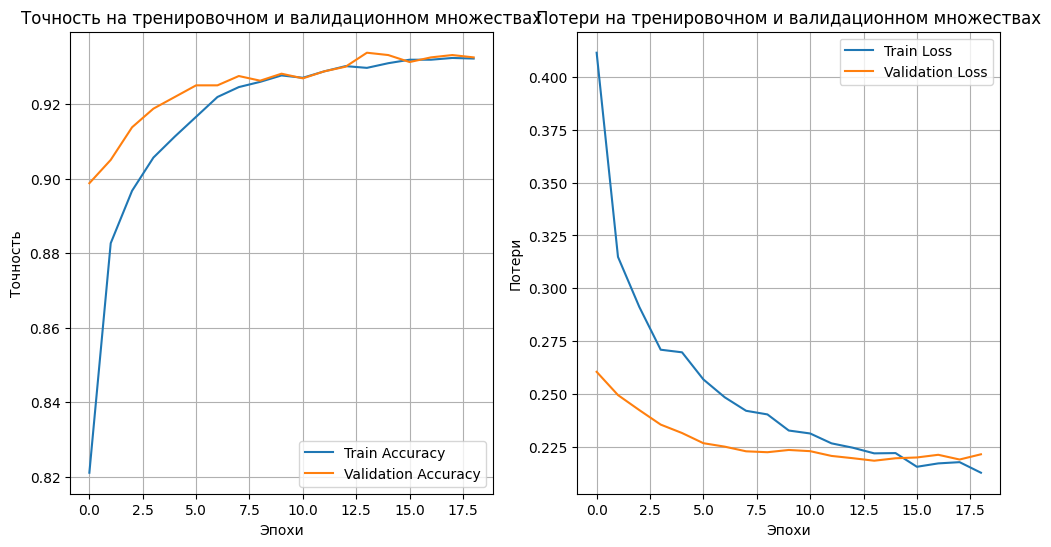

Точность на тестовом множестве: 0.9350
Потери на тестовом множестве: 0.1962


In [34]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification

# Генерация синтетических данных
X, y = make_classification(n_samples=10000, n_features=20, n_classes=2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Функция для создания модели
def create_model():
    model = Sequential([
        Input(shape=(X_train.shape[1],)),  # Явное указание входного слоя
        Dense(64, activation='relu'),
        Dropout(0.2),  # Добавляем дропаут
        Dense(32, activation='relu'),
        Dropout(0.2),  # Добавляем дропаут
        Dense(1, activation='sigmoid')  # Выходной слой для бинарной классификации
    ])
    model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])
    return model

# Создание модели
model = create_model()

# Настройка ранней остановки
early_stopping = EarlyStopping(
    monitor='val_loss',  # Отслеживаем потери на валидационном множестве
    patience=5,          # Останавливаем, если улучшений нет в течение 5 эпох
    min_delta=0.001,     # Минимальное изменение, считающееся улучшением
    restore_best_weights=True  # Восстанавливаем веса лучшей эпохи
)

# Обучение модели с ранней остановкой
history = model.fit(
    X_train, y_train,
    epochs=50,  # Максимальное количество эпох
    batch_size=32,
    validation_split=0.2,  # Валидационное множество
    callbacks=[early_stopping],  # Добавляем callback
    verbose=1
)

# Визуализация результатов
plt.figure(figsize=(12, 6))

# График точности
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Точность на тренировочном и валидационном множествах')
plt.xlabel('Эпохи')
plt.ylabel('Точность')
plt.legend()
plt.grid(True)

# График потерь
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Потери на тренировочном и валидационном множествах')
plt.xlabel('Эпохи')
plt.ylabel('Потери')
plt.legend()
plt.grid(True)

plt.show()

# Оценка модели на тестовом множестве
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Точность на тестовом множестве: {test_accuracy:.4f}")
print(f"Потери на тестовом множестве: {test_loss:.4f}")

# Подбор параметров
**Реализуйте подбор параметров сети Keras. Используйте keras_tuner.GridSearch
перебора.**

In [35]:
pip install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.1/129.1 kB 4.4 MB/s eta 0:00:00


In [36]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification
import keras_tuner as kt

# Генерация синтетических данных
X, y = make_classification(n_samples=10000, n_features=20, n_classes=2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Функция для создания модели с настраиваемыми гиперпараметрами
def build_model(hp):
    model = Sequential([
        Input(shape=(X_train.shape[1],)),  # Явное указание входного слоя
        Dense(units=hp.Int('units_1', min_value=32, max_value=128, step=32), activation='relu'),
        Dropout(rate=hp.Float('dropout_1', min_value=0.0, max_value=0.5, step=0.1)),
        Dense(units=hp.Int('units_2', min_value=16, max_value=64, step=16), activation='relu'),
        Dropout(rate=hp.Float('dropout_2', min_value=0.0, max_value=0.5, step=0.1)),
        Dense(1, activation='sigmoid')  # Выходной слой для бинарной классификации
    ])
    model.compile(
        optimizer=Adam(learning_rate=hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

# Инициализация GridSearch
tuner = kt.GridSearch(
    build_model,
    objective='val_accuracy',  # Целевая метрика для оптимизации
    executions_per_trial=3,    # Количество запусков для каждой комбинации гиперпараметров
    directory='keras_tuner_dir',  # Директория для сохранения результатов
    project_name='keras_tuner_example'
)

# Поиск по сетке
tuner.search(
    X_train, y_train,
    epochs=10,  # Количество эпох для каждого запуска
    batch_size=32,
    validation_split=0.2,  # Валидационное множество
    verbose=1
)

# Вывод лучших гиперпараметров
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print(f"Лучшие гиперпараметры:")
print(f"Количество нейронов в первом слое: {best_hps.get('units_1')}")
print(f"Дропаут в первом слое: {best_hps.get('dropout_1')}")
print(f"Количество нейронов во втором слое: {best_hps.get('units_2')}")
print(f"Дропаут во втором слое: {best_hps.get('dropout_2')}")
print(f"Скорость обучения: {best_hps.get('learning_rate')}")

# Обучение модели с лучшими гиперпараметрами
model = tuner.hypermodel.build(best_hps)
history = model.fit(
    X_train, y_train,
    epochs=50,  # Обучение на большее количество эпох
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# Визуализация результатов
plt.figure(figsize=(12, 6))

# График точности
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Точность на тренировочном и валидационном множествах')
plt.xlabel('Эпохи')
plt.ylabel('Точность')
plt.legend()
plt.grid(True)

# График потерь
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Потери на тренировочном и валидационном множествах')
plt.xlabel('Эпохи')
plt.ylabel('Потери')
plt.legend()
plt.grid(True)

plt.show()

# Оценка модели на тестовом множестве
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Точность на тестовом множестве: {test_accuracy:.4f}")
print(f"Потери на тестовом множестве: {test_loss:.4f}")

Trial 25 Complete [00h 00m 34s]
val_accuracy: 0.9356249968210856

Best val_accuracy So Far: 0.9356249968210856
Total elapsed time: 00h 13m 24s

Search: Running Trial #26

Value             |Best Value So Far |Hyperparameter
32                |32                |units_1
0                 |0                 |dropout_1
32                |16                |units_2
0.3               |0.3               |dropout_2
0.001             |0.01              |learning_rate

Epoch 1/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7018 - loss: 0.5569 - val_accuracy: 0.8875 - val_loss: 0.2846
Epoch 2/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8799 - loss: 0.3107 - val_accuracy: 0.9025 - val_loss: 0.2591
Epoch 3/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8927 - loss: 0.2999 - val_accuracy: 0.9150 - val_loss: 0.2433
Epoch 4/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9061 - loss: 0.2803 - val_accuracy: 0.9187 - val_loss: 0.2396
Epoch 5/10
200/200 ━━━━

KeyboardInterrupt: 